# Docking scores across exhaustiveness settings and design rounds

Loads every `data/output/docking_scores-exhaustiveness<N>.csv` (one per Vina
`exhaustiveness` value used), combines them into a single dataframe, and tags
each docked structure with the design it came from and that design's round
(`prot_<round>_<index>`, see `scripts/paths.py`). Both rounds are analyzed
together: strong binders (`best_affinity_kcal_mol <= -THRESHOLD`) are listed
per exhaustiveness, then compared between rounds -- hit counts per design, the
share of each round's designs with at least one hit, and the affinity
distributions.

In [1]:
import html
import os
import re
import shutil
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import HTML, display

REPO_ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(REPO_ROOT / "scripts"))
from paths import OUTPUT_DIR, design_label, input_designs, natural_key, parse_design_name

# Binding-affinity cutoff (kcal/mol). A structure counts as a "hit" when
# best_affinity_kcal_mol <= -THRESHOLD (i.e. binds at least this strongly --
# affinities are negative, more negative = stronger).
THRESHOLD = 6

# One fixed color per design round, assigned in round order (never cycled),
# so a round keeps its color across every chart. Non-design structures
# (the 6c2u reference and its NMR models, if docked) are neutral gray.
ROUND_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
REFERENCE_COLOR = "#8a8a85"

In [2]:
# Matches both the "exhaustiveness" and the misspelled "exhaustivness" file names.
FILENAME_RE = re.compile(r"^docking_scores-exhaustive?ness(\d+)\.csv$")

score_files = sorted(OUTPUT_DIR.glob("docking_scores-*.csv"), key=natural_key)
if not score_files:
    raise SystemExit(f"No docking_scores-*.csv files found in {OUTPUT_DIR}")

frames = []
for path in score_files:
    match = FILENAME_RE.match(path.name)
    if not match:
        print(f"Skipping {path.name}: doesn't match the expected naming pattern")
        continue
    df = pd.read_csv(path)
    df["exhaustiveness"] = int(match.group(1))
    frames.append(df)

scores = pd.concat(frames, ignore_index=True)

# design: the design a structure belongs to, so its _flex / _relaxed_000N
# variants group together (6c2u's NMR models fold into "6c2u").
# round: that design's round, or <NA> for anything that isn't a design.
scores["design"] = scores["receptor"].map(design_label)
scores["round"] = pd.array(
    [parsed[0] if parsed else None for parsed in scores["design"].map(parse_design_name)],
    dtype="Int64",
)
scores["round_label"] = [f"round {r}" if pd.notna(r) else "reference" for r in scores["round"]]

scores = scores.sort_values(["exhaustiveness", "best_affinity_kcal_mol"]).reset_index(drop=True)

round_labels = sorted(scores["round_label"].unique(), key=natural_key)
round_palette = {
    label: REFERENCE_COLOR if label == "reference"
    else ROUND_COLORS[(int(label.split()[1]) - 1) % len(ROUND_COLORS)]
    for label in round_labels
}
scores

,receptor,best_affinity_kcal_mol,exhaustiveness,design,round,round_label
0,prot_2_6_relaxed_0005,-7.243,4,prot_2_6,2,round 2
1,prot_2_1_relaxed_0003,-7.214,4,prot_2_1,2,round 2
2,prot_2_6_relaxed_0002,-7.098,4,prot_2_6,2,round 2
3,prot_1_3_relaxed_0001,-7.063,4,prot_1_3,1,round 1
4,prot_2_1_relaxed_0005_flex,-7.028,4,prot_2_1,2,round 2
...,...,...,...,...,...,...
2115,prot_2_19_relaxed_0002,-4.613,1024,prot_2_19,2,round 2
2116,prot_1_4_relaxed_0002,-4.189,1024,prot_1_4,1,round 1
2117,prot_1_4_relaxed_0001,-4.159,1024,prot_1_4,1,round 1
2118,prot_1_4_relaxed_0005,-4.149,1024,prot_1_4,1,round 1


## Coverage

Which designs in `data/input/` made it into the score tables -- a design with
no rows (e.g. its receptor preparation failed) silently drops out of every
comparison below, which would skew its round's hit rate.

In [3]:
input_by_round = {}
for path in input_designs():
    input_by_round.setdefault(parse_design_name(path)[0], []).append(path.stem)

coverage = (
    scores.groupby(["round_label", "exhaustiveness"])
    .agg(designs=("design", "nunique"), structures=("receptor", "nunique"))
    .unstack("exhaustiveness")
)
display(coverage)

docked_designs = set(scores["design"])
for rnd, designs in sorted(input_by_round.items()):
    missing = [d for d in designs if d not in docked_designs]
    print(f"round {rnd}: {len(designs)} designs in data/input/, {len(designs) - len(missing)} docked"
          + (f" -- missing: {', '.join(missing)}" if missing else ""))

designs                     structures                    
exhaustiveness    4    64   128  512  1024       4    64   128  512  1024
round_label                                                              
round 1              7    7    7    7    7         80   80   80   80   80
round 2             29   29   29   29   29        344  344  344  344  344

round 1: 8 designs in data/input/, 7 docked -- missing: prot_1_6
round 2: 30 designs in data/input/, 29 docked -- missing: prot_2_16


## Hits per exhaustiveness

In [4]:
ex_hits = {}
for exhaustiveness, group in scores.groupby("exhaustiveness"):
    hits = group[group["best_affinity_kcal_mol"] <= -THRESHOLD].sort_values("best_affinity_kcal_mol")
    ex_hits[exhaustiveness] = hits
    per_round = hits["round_label"].value_counts()
    per_round_text = ", ".join(f"{label}: {per_round.get(label, 0)}" for label in round_labels)
    print(f"exhaustiveness={exhaustiveness}: {len(hits)} structure(s) at or below -{THRESHOLD} kcal/mol"
          f" ({per_round_text})")
    display(hits[["receptor", "round_label", "best_affinity_kcal_mol"]])

exhaustiveness=4: 111 structure(s) at or below -6 kcal/mol (round 1: 19, round 2: 92)


,receptor,round_label,best_affinity_kcal_mol
0,prot_2_6_relaxed_0005,round 2,-7.243
1,prot_2_1_relaxed_0003,round 2,-7.214
2,prot_2_6_relaxed_0002,round 2,-7.098
3,prot_1_3_relaxed_0001,round 1,-7.063
4,prot_2_1_relaxed_0005_flex,round 2,-7.028
...,...,...,...
106,prot_1_7_relaxed_0005,round 1,-6.013
107,prot_2_29_relaxed_0001,round 2,-6.010
108,prot_2_20,round 2,-6.006
109,prot_2_26_relaxed_0004_flex,round 2,-6.005


exhaustiveness=64: 166 structure(s) at or below -6 kcal/mol (round 1: 31, round 2: 135)


,receptor,round_label,best_affinity_kcal_mol
424,prot_2_6_relaxed_0002,round 2,-7.563
425,prot_2_6_relaxed_0002_flex,round 2,-7.485
426,prot_2_1_relaxed_0005_flex,round 2,-7.475
427,prot_2_1_relaxed_0004,round 2,-7.457
428,prot_1_3_relaxed_0005,round 1,-7.394
...,...,...,...
585,prot_2_26_relaxed_0004,round 2,-6.006
586,prot_2_27_flex,round 2,-6.005
587,prot_2_20_relaxed_0002_flex,round 2,-6.004
588,prot_2_24_relaxed_0005,round 2,-6.003


exhaustiveness=128: 172 structure(s) at or below -6 kcal/mol (round 1: 29, round 2: 143)


,receptor,round_label,best_affinity_kcal_mol
848,prot_2_6_relaxed_0002,round 2,-7.589
849,prot_2_6_relaxed_0002_flex,round 2,-7.526
850,prot_2_1_relaxed_0004,round 2,-7.500
851,prot_2_6_relaxed_0005,round 2,-7.438
852,prot_2_6_relaxed_0005_flex,round 2,-7.433
...,...,...,...
1015,prot_2_27_flex,round 2,-6.012
1016,prot_2_3_relaxed_0002,round 2,-6.008
1017,prot_2_4_relaxed_0001_flex,round 2,-6.007
1018,prot_2_26_relaxed_0001_flex,round 2,-6.006


exhaustiveness=512: 181 structure(s) at or below -6 kcal/mol (round 1: 32, round 2: 149)


,receptor,round_label,best_affinity_kcal_mol
1272,prot_2_6_relaxed_0005,round 2,-7.687
1273,prot_2_6_relaxed_0002,round 2,-7.617
1274,prot_2_6_relaxed_0002_flex,round 2,-7.503
1275,prot_2_1_relaxed_0004,round 2,-7.494
1276,prot_2_6_relaxed_0005_flex,round 2,-7.444
...,...,...,...
1448,prot_2_28_flex,round 2,-6.019
1449,prot_2_22_flex,round 2,-6.018
1450,prot_2_27_flex,round 2,-6.009
1451,prot_2_19_relaxed_0005_flex,round 2,-6.007


exhaustiveness=1024: 185 structure(s) at or below -6 kcal/mol (round 1: 36, round 2: 149)


,receptor,round_label,best_affinity_kcal_mol
1696,prot_2_6_relaxed_0005,round 2,-7.696
1697,prot_2_6_relaxed_0002,round 2,-7.589
1698,prot_2_1_relaxed_0004,round 2,-7.469
1699,prot_1_3_relaxed_0005,round 1,-7.430
1700,prot_2_6_relaxed_0002_flex,round 2,-7.388
...,...,...,...
1876,prot_2_29_relaxed_0003,round 2,-6.019
1877,prot_2_3_relaxed_0003,round 2,-6.010
1878,prot_2_28_flex,round 2,-6.009
1879,prot_2_24_relaxed_0005,round 2,-6.004


## Round 1 vs. round 2

Rounds differ in size (and a design may be missing, see Coverage), so raw hit
counts aren't comparable on their own -- `pct_designs_with_hit` is the share
of a round's docked designs with at least one structure (any `_flex` /
`_relaxed_000N` variant) at or below the threshold.

In [5]:
def round_summary(group):
    is_hit = group["best_affinity_kcal_mol"] <= -THRESHOLD
    designs = group["design"].nunique()
    designs_with_hit = group.loc[is_hit, "design"].nunique()
    return pd.Series({
        "designs": designs,
        "structures": len(group),
        "hits": int(is_hit.sum()),
        "designs_with_hit": designs_with_hit,
        "pct_designs_with_hit": round(100 * designs_with_hit / designs, 1),
        "best_affinity": group["best_affinity_kcal_mol"].min(),
        "median_affinity": group["best_affinity_kcal_mol"].median(),
    })


summary = (
    scores.groupby(["exhaustiveness", "round_label"])[["design", "best_affinity_kcal_mol"]]
    .apply(round_summary)
    .astype({"designs": int, "structures": int, "hits": int, "designs_with_hit": int})
)
summary

designs  structures  hits  designs_with_hit  \
exhaustiveness round_label                                                
4              round 1            7          80    19                 4   
               round 2           29         344    92                18   
64             round 1            7          80    31                 6   
               round 2           29         344   135                23   
128            round 1            7          80    29                 5   
               round 2           29         344   143                26   
512            round 1            7          80    32                 5   
               round 2           29         344   149                24   
1024           round 1            7          80    36                 6   
               round 2           29         344   149                25   

                            pct_designs_with_hit  best_affinity  \
exhaustiveness round_label                                        
4              round 1                      57.1         -7.063   
               round 2                      62.1         -7.243   
64             round 1                      85.7         -7.394   
               round 2                      79.3         -7.563   
128            round 1                      71.4         -7.409   
               round 2                      89.7         -7.589   
512            round 1                      71.4         -7.375   
               round 2                      82.8         -7.687   
1024           round 1                      85.7         -7.430   
               round 2                      86.2         -7.696   

                            median_affinity  
exhaustiveness round_label                   
4              round 1              -5.4960  
               round 2              -5.5645  
64             round 1              -5.8905  
               round 2              -5.8940  
128            round 1              -5.8465  
               round 2              -5.9095  
512            round 1              -5.9030  
               round 2              -5.9235  
1024           round 1              -5.9490  
               round 2              -5.9540

In [6]:
# Group each hit under the design it came from, so a design's variants
# (_flex, _relaxed_000N) count together. Designs are named
# prot_<round>_<index>, so splitting on the first underscore would put every
# one of them in a single "prot" bucket -- design_label (scripts/paths.py)
# keeps the full prot_<round>_<index> and folds 6c2u's NMR models into "6c2u".
design_sets = {}
design_hit_counts = {}

for ex, hits in ex_hits.items():
    designs = hits["receptor"].map(design_label)
    unique_designs = designs.drop_duplicates().tolist()
    counts = designs.value_counts().to_dict()

    design_sets[ex] = unique_designs
    design_hit_counts[ex] = {design: counts[design] for design in unique_designs}

    print(f"exhaustiveness={ex}:")
    for design in unique_designs:
        print(f"  {design}: {design_hit_counts[ex][design]}")

exhaustiveness=4:
  prot_2_6: 10
  prot_2_1: 11
  prot_1_3: 9
  prot_2_9: 5
  prot_2_10: 7
  prot_2_11: 11
  prot_2_22: 2
  prot_2_20: 7
  prot_2_23: 4
  prot_2_5: 2
  prot_2_24: 7
  prot_2_25: 8
  prot_2_7: 6
  prot_1_1: 5
  prot_2_17: 4
  prot_1_2: 3
  prot_2_2: 1
  prot_1_7: 2
  prot_2_27: 3
  prot_2_26: 2
  prot_2_3: 1
  prot_2_29: 1
exhaustiveness=64:
  prot_2_6: 11
  prot_2_1: 11
  prot_1_3: 10
  prot_2_9: 11
  prot_2_24: 8
  prot_2_10: 12
  prot_2_11: 11
  prot_1_2: 6
  prot_2_17: 8
  prot_2_5: 4
  prot_2_13: 2
  prot_2_20: 8
  prot_2_25: 9
  prot_2_7: 2
  prot_1_7: 7
  prot_2_23: 9
  prot_1_1: 6
  prot_2_22: 3
  prot_2_26: 6
  prot_2_27: 6
  prot_2_2: 1
  prot_2_3: 3
  prot_1_8: 1
  prot_2_0: 3
  prot_2_12: 1
  prot_1_5: 1
  prot_2_29: 4
  prot_2_8: 1
  prot_2_14: 1
exhaustiveness=128:
  prot_2_6: 12
  prot_2_1: 11
  prot_1_3: 10
  prot_2_9: 10
  prot_2_10: 11
  prot_2_24: 8
  prot_2_11: 11
  prot_2_17: 8
  prot_1_2: 4
  prot_2_25: 9
  prot_1_1: 6
  prot_2_7: 4
  prot_2_22: 6
 

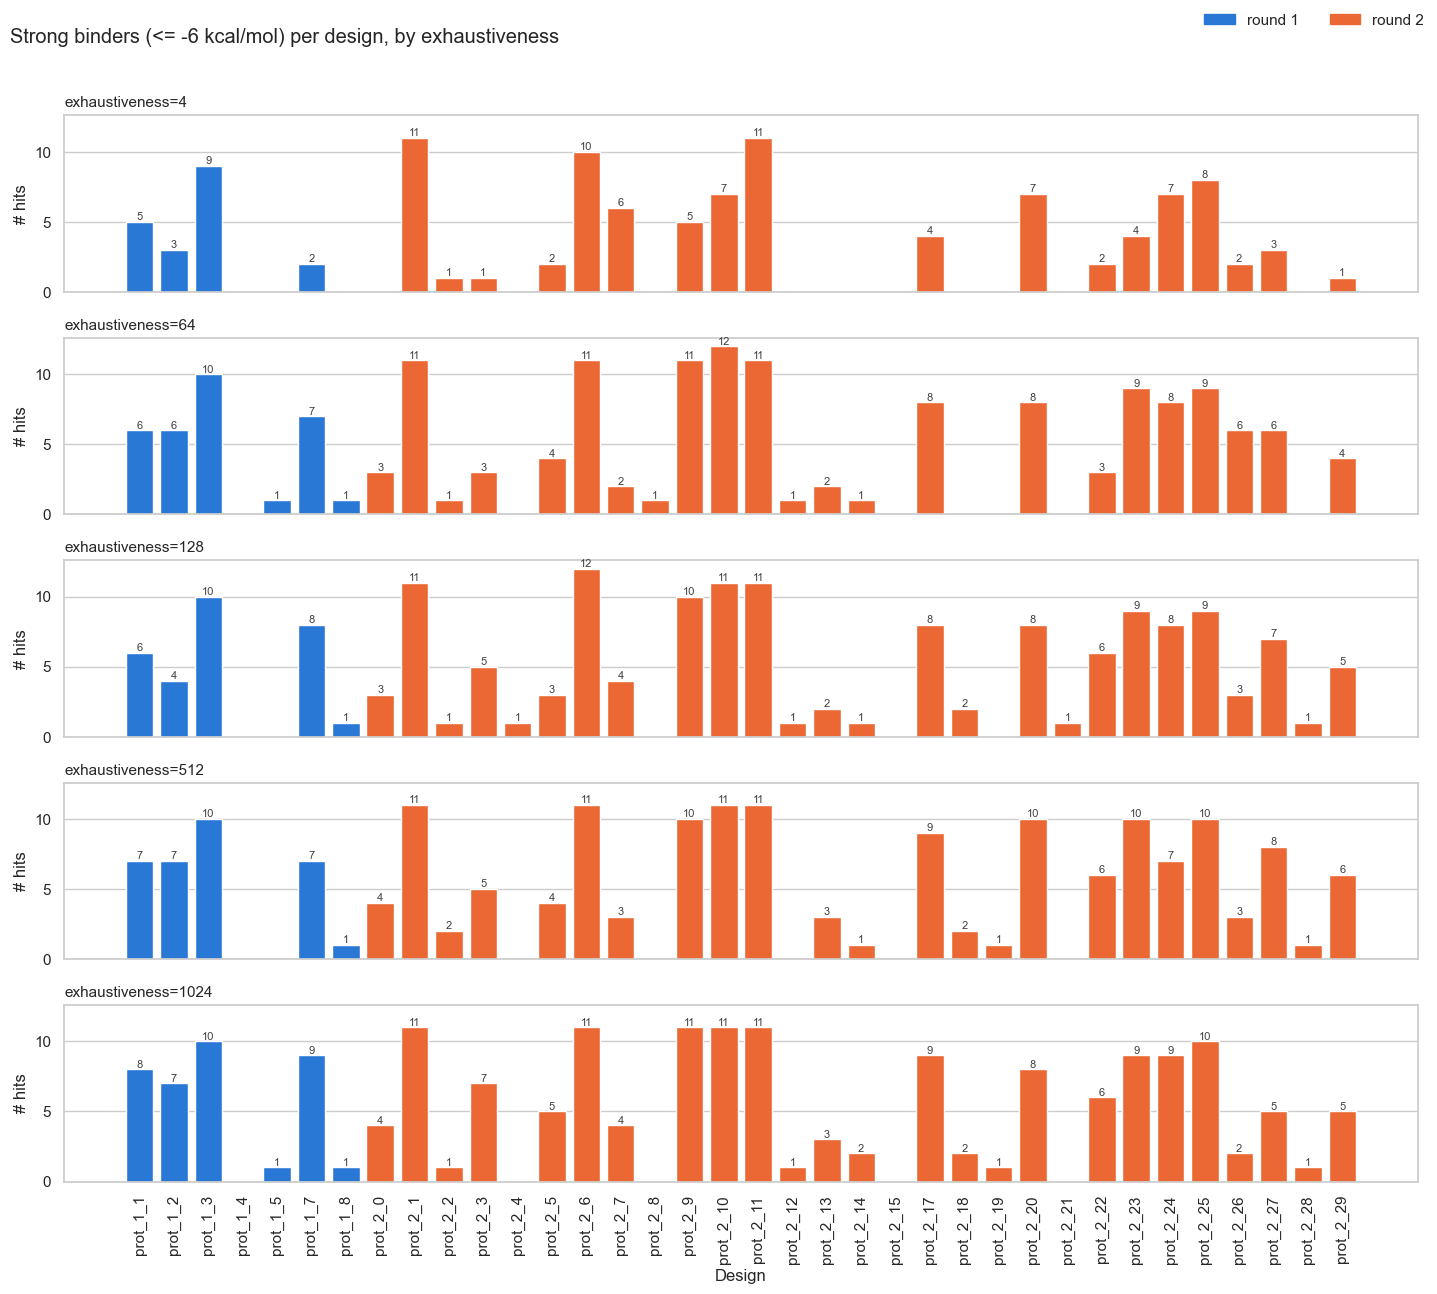

In [7]:
sns.set_theme(style="whitegrid")

exhaustivenesses = sorted(ex_hits.keys())
# Every docked design, not just those with hits, so a round's misses show up
# as empty slots next to the other round's hits.
all_designs = sorted(scores["design"].unique(), key=natural_key)
design_round = scores.drop_duplicates("design").set_index("design")["round_label"]
bar_colors = [round_palette[design_round[design]] for design in all_designs]

fig, axes = plt.subplots(
    len(exhaustivenesses), 1,
    figsize=(max(10, 0.4 * len(all_designs)), 2.6 * len(exhaustivenesses)),
    sharex=True, sharey=True,
)
if len(exhaustivenesses) == 1:
    axes = [axes]

for ax, ex in zip(axes, exhaustivenesses):
    counts = [design_hit_counts[ex].get(design, 0) for design in all_designs]
    bars = ax.bar(all_designs, counts, color=bar_colors, width=0.8)

    for bar, count in zip(bars, counts):
        if count:
            ax.text(bar.get_x() + bar.get_width() / 2, count, f"{count}",
                    ha="center", va="bottom", fontsize=8, color="0.25")

    ax.set_title(f"exhaustiveness={ex}", loc="left", fontsize=11)
    ax.set_ylabel("# hits")
    ax.grid(axis="x", visible=False)

axes[-1].tick_params(axis="x", rotation=90)
axes[-1].set_xlabel("Design")
handles = [plt.Rectangle((0, 0), 1, 1, color=round_palette[label]) for label in round_labels]
fig.legend(handles, round_labels, loc="upper right", ncol=len(round_labels), frameon=False)
fig.suptitle(f"Strong binders (<= -{THRESHOLD} kcal/mol) per design, by exhaustiveness",
             x=0.01, ha="left")
fig.tight_layout(rect=(0, 0, 1, 0.97))
plt.show()

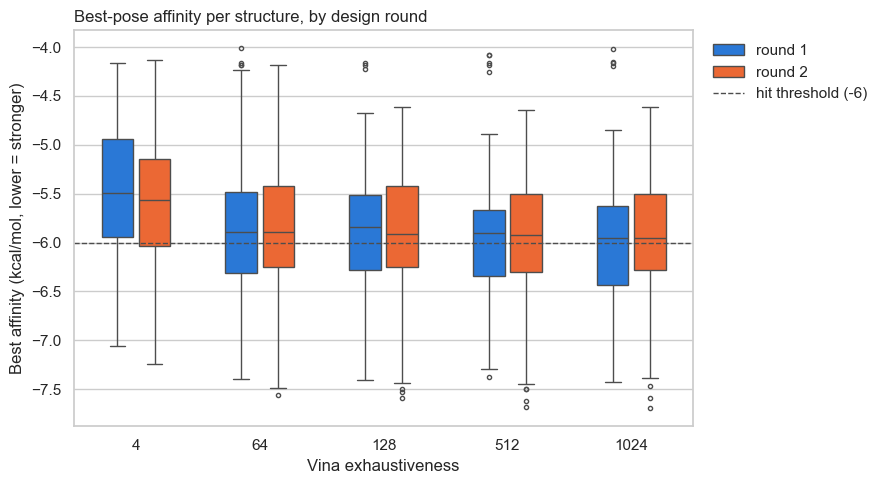

In [8]:
# Affinity distribution of every docked structure, per round: is one round
# shifted toward stronger binding than the other, at every exhaustiveness?
# Dashed line = the hit threshold.
fig, ax = plt.subplots(figsize=(max(8, 1.8 * len(exhaustivenesses)), 5))
sns.boxplot(
    data=scores, x="exhaustiveness", y="best_affinity_kcal_mol",
    hue="round_label", hue_order=round_labels, palette=round_palette,
    width=0.6, gap=0.15, fliersize=3, linewidth=1, saturation=1, ax=ax,
)
ax.axhline(-THRESHOLD, color="0.3", linestyle="--", linewidth=1, label=f"hit threshold (-{THRESHOLD})")
ax.set_ylabel("Best affinity (kcal/mol, lower = stronger)")
ax.set_xlabel("Vina exhaustiveness")
ax.legend(title=None, frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))
ax.set_title("Best-pose affinity per structure, by design round", loc="left")
fig.tight_layout()
plt.show()

## Best affinity per design

Each design's strongest structure (over all its `_flex` / `_relaxed_000N`
variants) at every exhaustiveness, ranked by the mean across exhaustiveness
values.

In [9]:
best_per_design = (
    scores.groupby(["design", "round_label", "exhaustiveness"])["best_affinity_kcal_mol"].min()
    .unstack("exhaustiveness")
)
best_per_design["mean"] = best_per_design.mean(axis=1)
best_per_design = best_per_design.sort_values("mean")
best_per_design.round(2)

,exhaustiveness,4,64,128,512,1024,mean
design,round_label,,,,,,
prot_2_6,round 2,-7.24,-7.56,-7.59,-7.69,-7.70,-7.56
prot_2_1,round 2,-7.21,-7.48,-7.50,-7.49,-7.47,-7.43
prot_1_3,round 1,-7.06,-7.39,-7.41,-7.38,-7.43,-7.33
prot_2_9,round 2,-6.92,-7.32,-7.30,-7.26,-7.31,-7.22
prot_2_10,round 2,-6.89,-6.95,-7.18,-7.32,-7.20,-7.11
prot_2_24,round 2,-6.50,-7.11,-6.97,-7.11,-7.09,-6.96
prot_2_11,round 2,-6.68,-6.83,-6.94,-6.93,-6.93,-6.86
prot_2_17,round 2,-6.35,-6.72,-6.89,-6.86,-6.73,-6.71
prot_1_2,round 1,-6.25,-6.73,-6.64,-6.86,-6.93,-6.68


## Best structure per design, by round

One table per design round, one row per design: the single structure -- out
of all the design's variants (rigid and `_flex`, original and
`_relaxed_000N`) and all exhaustiveness values -- with the strongest
best-pose affinity. `receptor` is that structure, `best_affinity` its
affinity and `best_exhaustiveness` the exhaustiveness it was reached at (on a
tie, the lowest exhaustiveness, then the first receptor in natural order); the
numbered columns are that same receptor's affinity at every exhaustiveness.
Rows are ranked strongest first; `hit` marks `best_affinity <= -THRESHOLD`. The
`pymol_script` column links to the PyMOL viewer for that receptor at its
`best_exhaustiveness` (`data/output/vina_poses-exhaustiveness<N>/<receptor>_view.pml`,
written by `05_generate_pymol_scripts.py`). Below each table, pick a design
and press **Open in PyMOL** to launch PyMOL on its viewer -- this needs
`ipywidgets` in this kernel and PyMOL on PATH (or `PYMOL_BIN` set to its
executable).

In [10]:
by_structure = scores.pivot_table(
    index=["round_label", "design", "receptor"], columns="exhaustiveness",
    values="best_affinity_kcal_mol", aggfunc="min",
)
by_structure.columns.name = None
by_structure["best_affinity"] = by_structure[exhaustivenesses].min(axis=1)
# Columns are ascending exhaustiveness, so idxmin's first-occurrence rule
# picks the lowest exhaustiveness on a tie.
by_structure["best_exhaustiveness"] = by_structure[exhaustivenesses].idxmin(axis=1).astype(int)
by_structure = by_structure.reset_index()

# Each design's single strongest structure: sort strongest first (ties broken
# by natural receptor order) and keep the first row per design.
by_structure["_order"] = by_structure["receptor"].map(natural_key)
best_structure = (
    by_structure.sort_values(["best_affinity", "_order"])
    .drop_duplicates("design")
    .drop(columns="_order")
)
best_structure["hit"] = best_structure["best_affinity"] <= -THRESHOLD

# The PyMOL viewer for that receptor's poses at that exhaustiveness, written by
# 05_generate_pymol_scripts.py next to the poses (04_run_docking.sh puts
# VINA_EXHAUSTIVENESS=<N> runs in vina_poses-exhaustiveness<N>/).
def pymol_script(row):
    return OUTPUT_DIR / f"vina_poses-exhaustiveness{row['best_exhaustiveness']}" / f"{row['receptor']}_view.pml"


def pymol_link(path):
    # Relative to the notebook, so the link resolves wherever the repo lives
    # (VS Code and JupyterLab resolve relative links against the notebook).
    if not path.exists():
        return "missing -- run 05_generate_pymol_scripts.py"
    href = Path(os.path.relpath(path, Path.cwd())).as_posix()
    return f'<a href="{html.escape(href)}">{html.escape(path.name)}</a>'


best_structure["pymol_script"] = best_structure.apply(pymol_script, axis=1)
columns = ["design", "receptor", "best_affinity", "best_exhaustiveness", "hit", *exhaustivenesses, "pymol_script"]

# PyMOL to launch from the "Open in PyMOL" button: $PYMOL_BIN if set, else
# `pymol` on PATH. It's a separate program, not imported into this kernel.
PYMOL_BIN = os.environ.get("PYMOL_BIN") or shutil.which("pymol")

try:
    import ipywidgets as widgets
except ImportError:
    widgets = None


def open_in_pymol(script, log):
    with log:
        log.clear_output()
        try:
            # Detached, so PyMOL keeps running independently of the kernel;
            # no extra console window on Windows. The script chdirs into its
            # own directory itself, so PyMOL's working directory doesn't matter.
            subprocess.Popen(
                [PYMOL_BIN, str(script)],
                stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL,
                creationflags=getattr(subprocess, "CREATE_NO_WINDOW", 0),
            )
            print(f"Opened {script.name} in PyMOL")
        except OSError as error:
            print(f"Couldn't start PyMOL ({PYMOL_BIN}): {error}")


def pymol_picker(table):
    """Dropdown of the table's receptors + an Open in PyMOL button."""
    options = [
        (f"{row['design']}: {row['receptor']} (exhaustiveness {row['best_exhaustiveness']})", row["pymol_script"])
        for _, row in table.iterrows() if row["pymol_script"].exists()
    ]
    picker = widgets.Dropdown(options=options, layout=widgets.Layout(width="max-content"))
    button = widgets.Button(description="Open in PyMOL", icon="external-link", button_style="primary")
    log = widgets.Output()
    button.on_click(lambda _: open_in_pymol(picker.value, log))
    return widgets.VBox([widgets.HBox([picker, button]), log])


for label in round_labels:
    table = best_structure[best_structure["round_label"] == label][columns].reset_index(drop=True)
    print(f"{label}: {len(table)} designs, {int(table['hit'].sum())} with a hit")
    # Always the plain-HTML table (not .style, which needs jinja2), so it shows
    # even where widgets don't render; the PyMOL button is an extra below it.
    display(HTML(table.to_html(
        escape=False, float_format="{:.3f}".format,
        formatters={"pymol_script": pymol_link},
    )))
    if widgets is None:
        print("(pip install ipywidgets in this kernel for an Open in PyMOL button)")
    elif PYMOL_BIN is None:
        print("(PyMOL not found on PATH -- set PYMOL_BIN to its executable for an Open in PyMOL button)")
    else:
        display(pymol_picker(table))

round 1: 7 designs, 6 with a hit


,design,receptor,best_affinity,best_exhaustiveness,hit,4,64,128,512,1024,pymol_script
0,prot_1_3,prot_1_3_relaxed_0005,-7.430,1024,True,-6.437,-7.394,-7.409,-7.375,-7.430,prot_1_3_relaxed_0005_view.pml
1,prot_1_2,prot_1_2_relaxed_0004,-6.930,1024,True,-5.610,-5.414,-5.820,-5.717,-6.930,prot_1_2_relaxed_0004_view.pml
2,prot_1_7,prot_1_7_relaxed_0003_flex,-6.571,1024,True,-5.468,-6.504,-6.346,-6.452,-6.571,prot_1_7_relaxed_0003_flex_view.pml
3,prot_1_1,prot_1_1_relaxed_0001,-6.552,128,True,-6.115,-6.416,-6.552,-6.463,-6.486,prot_1_1_relaxed_0001_view.pml
4,prot_1_8,prot_1_8_flex,-6.380,1024,True,-5.879,-6.148,-6.288,-6.283,-6.380,prot_1_8_flex_view.pml
5,prot_1_5,prot_1_5_flex,-6.282,1024,True,-5.753,-5.809,-5.824,-5.876,-6.282,prot_1_5_flex_view.pml
6,prot_1_4,prot_1_4_relaxed_0001_flex,-5.205,1024,False,-4.496,-4.237,-4.223,-4.933,-5.205,prot_1_4_relaxed_0001_flex_view.pml


round 2: 29 designs, 28 with a hit


,design,receptor,best_affinity,best_exhaustiveness,hit,4,64,128,512,1024,pymol_script
0,prot_2_6,prot_2_6_relaxed_0005,-7.696,1024,True,-7.243,-7.349,-7.438,-7.687,-7.696,prot_2_6_relaxed_0005_view.pml
1,prot_2_1,prot_2_1_relaxed_0004,-7.500,128,True,-6.857,-7.457,-7.500,-7.494,-7.469,prot_2_1_relaxed_0004_view.pml
2,prot_2_9,prot_2_9_relaxed_0004,-7.321,64,True,-6.120,-7.321,-7.300,-7.258,-7.311,prot_2_9_relaxed_0004_view.pml
3,prot_2_10,prot_2_10_relaxed_0005_flex,-7.315,512,True,-6.893,-6.948,-7.182,-7.315,-7.196,prot_2_10_relaxed_0005_flex_view.pml
4,prot_2_24,prot_2_24_relaxed_0002,-7.114,64,True,-6.462,-7.114,-6.967,-7.114,-7.092,prot_2_24_relaxed_0002_view.pml
5,prot_2_11,prot_2_11_flex,-6.937,128,True,-6.254,-6.564,-6.937,-6.925,-6.929,prot_2_11_flex_view.pml
6,prot_2_17,prot_2_17_flex,-6.889,128,True,-6.267,-6.280,-6.889,-6.863,-6.540,prot_2_17_flex_view.pml
7,prot_2_7,prot_2_7,-6.814,1024,True,-5.661,-6.556,-6.542,-6.582,-6.814,prot_2_7_view.pml
8,prot_2_5,prot_2_5_relaxed_0005,-6.725,512,True,-6.549,-6.716,-6.364,-6.725,-6.718,prot_2_5_relaxed_0005_view.pml
9,prot_2_13,prot_2_13_relaxed_0002,-6.680,512,True,-5.255,-6.659,-5.808,-6.680,-6.660,prot_2_13_relaxed_0002_view.pml
